# 1. Data Exploration
## Imports

In [131]:

import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

data_path = "../data/raw/"

## Dataset loading

In [113]:
# WHO - Physical activity
who_physical_activity = pd.read_csv(
    data_path + "who/who_physical_activity.csv"
)

# Eurostat - Obesity
with open(
    data_path + "eurostat/eurostat_obesity.json",
    encoding="utf-8"
) as file:
    obesity_json = json.load(file)

# Eurostat - GDP per capita
with open(
    data_path + "eurostat/eurostat_gdp_2022.json",
    encoding="utf-8"
) as file:
    gdp_json = json.load(file)

## Data Dictionary   

This section describes the variables available in each dataset,
their meaning, units of measurement, and relevance to the analysis.

### 1. WHO – Physical Activity

| Column | Description | Unit / Values | Relevance |
|---|---|---|---|
| `Id` | Unique identifier of the observation | Numeric identifier | Technical identification |
| `IndicatorCode` | WHO indicator code | `NCD_PAA` | Identifies the physical inactivity indicator |
| `SpatialDimType` | Type of geographic dimension | Country, etc. | Identifies the geographic level |
| `SpatialDim` | Geographic identifier | ISO alpha-3 geographic identifier (e.g. `BGR`) | Used to match countries across datasets |
| `ParentLocationCode` | Code of the parent geographic region | WHO region code | Provides regional context |
| `ParentLocation` | Name of the parent geographic region | Region name | Provides regional context |
| `TimeDimType` | Type of time dimension | Year | Identifies the time dimension |
| `TimeDim` | Observation year | Year (e.g. `2022`) | Used to filter the analysis period |
| `Dim1Type` | Type of first disaggregation dimension | Sex | Identifies the population group |
| `Dim1` | Sex category | SEX_FMLE, SEX_MLE, SEX_BTSX | Used to select the overall adult population |
| `Dim2Type` | Type of second disaggregation dimension | Age | Identifies the age dimension |
| `Dim2` | 	Age-group category code | AGEGROUP_YEARS18-PLUS, AGEGROUP_YEARS60-69, etc. | Used to select adults aged 18+ |
| `Dim3Type` | Type of third disaggregation dimension | Not populated | Not used in this analysis |
| `Dim3` | Third disaggregation category | Not populated | Not used in this analysis |
| `DataSourceDimType` | Type of data-source dimension | Not populated | Not used in this analysis |
| `DataSourceDim` | Data-source dimension value | Not populated | Not used in this analysis |
| `Value` | Formatted prevalence estimate including uncertainty interval | Percentage and uncertainty interval | Human-readable result |
| `NumericValue` | Numerical estimate of physical inactivity prevalence | Percentage (%) | Main variable for the analysis |
| `Low` | Lower bound of the uncertainty interval | Percentage (%) | Indicates uncertainty around the estimate |
| `High` | Upper bound of the uncertainty interval | Percentage (%) | Indicates uncertainty around the estimate |
| `Comments` | Additional information about the observation | Text | Supplementary context |
| `Date` | Date associated with the observation | Date | Metadata |
| `TimeDimensionValue` | Time dimension value | Year | Alternative time representation |
| `TimeDimensionBegin` | Beginning of the time period | Date | Metadata |
| `TimeDimensionEnd` | End of the time period | Date | Metadata |

# 2. Initial Data Inspection

The purpose of this stage is to understand the structure, content, and quality of the datasets before performing any transformations or statistical analysis.

We will inspect:

- Dataset dimensions and column names.
- Data types and missing values.
- Available geographical locations and time periods.
- Population dimensions and indicator definitions.
- Potential inconsistencies that may affect the analysis.

## 2.1 WHO Physical Activity

The WHO dataset contains estimates of insufficient physical activity among adults aged 18 and above. It includes observations across multiple countries, years, genders, and age groups.

The initial exploration will help us identify the appropriate population categories and geographical coverage for our analysis.

In [114]:
# records and columns in the dataset
who_physical_activity.shape

(41262, 25)

In [115]:
who_physical_activity.head(5)

,Id,IndicatorCode,SpatialDimType,SpatialDim,ParentLocationCode,TimeDimType,ParentLocation,Dim1Type,TimeDim,Dim1,...,DataSourceDim,Value,NumericValue,Low,High,Comments,Date,TimeDimensionValue,TimeDimensionBegin,TimeDimensionEnd
0,27,NCD_PAA,COUNTRY,KNA,AMR,YEAR,Americas,SEX,2015,SEX_BTSX,...,NaN,38.6 [24.0-53.8],38.649147,24.015909,53.761047,NaN,2024-06-21T13:42:48.827+02:00,2015,2015-01-01T00:00:00+01:00,2015-12-31T00:00:00+01:00
1,551,NCD_PAA,COUNTRY,WSM,WPR,YEAR,Western Pacific,SEX,2007,SEX_BTSX,...,NaN,28.9 [22.9-35.3],28.883972,22.874971,35.296017,NaN,2024-06-21T13:42:48.827+02:00,2007,2007-01-01T00:00:00+01:00,2007-12-31T00:00:00+01:00
2,2450,NCD_PAA,COUNTRY,JPN,WPR,YEAR,Western Pacific,SEX,2006,SEX_MLE,...,NaN,29.5 [13.7-50.6],29.484329,13.722679,50.564968,NaN,2024-06-21T13:42:48.827+02:00,2006,2006-01-01T00:00:00+01:00,2006-12-31T00:00:00+01:00
3,2470,NCD_PAA,GLOBAL,GLOBAL,NaN,YEAR,NaN,SEX,2002,SEX_MLE,...,NaN,21.5 [18.7-24.7],21.511904,18.698532,24.674263,NaN,2024-06-21T13:42:48.827+02:00,2002,2002-01-01T00:00:00+01:00,2002-12-31T00:00:00+01:00
4,2512,NCD_PAA,COUNTRY,SDN,EMR,YEAR,Eastern Mediterranean,SEX,2006,SEX_FMLE,...,NaN,24.6 [10.8-42.5],24.585480,10.847883,42.450493,NaN,2024-06-21T13:42:48.827+02:00,2006,2006-01-01T00:00:00+01:00,2006-12-31T00:00:00+01:00


In [116]:
#understanding general info for our WHO dataset
who_physical_activity.info()

<class 'pandas.DataFrame'>
RangeIndex: 41262 entries, 0 to 41261
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  41262 non-null  int64  
 1   IndicatorCode       41262 non-null  str    
 2   SpatialDimType      41262 non-null  str    
 3   SpatialDim          41262 non-null  str    
 4   ParentLocationCode  40503 non-null  str    
 5   TimeDimType         41262 non-null  str    
 6   ParentLocation      40503 non-null  str    
 7   Dim1Type            41262 non-null  str    
 8   TimeDim             41262 non-null  int64  
 9   Dim1                41262 non-null  str    
 10  Dim2Type            41262 non-null  str    
 11  Dim2                41262 non-null  str    
 12  Dim3Type            0 non-null      float64
 13  Dim3                0 non-null      float64
 14  DataSourceDimType   0 non-null      float64
 15  DataSourceDim       0 non-null      float64
 16  Value          

In [117]:
who_physical_activity.describe()

,Id,TimeDim,Dim3Type,Dim3,DataSourceDimType,DataSourceDim,NumericValue,Low,High,TimeDimensionValue
count,4.126200e+04,41262.00000,0.0,0.0,0.0,0.0,41262.000000,41262.000000,41262.000000,41262.00000
mean,2.733070e+06,2011.00000,NaN,NaN,NaN,NaN,39.237174,24.630010,54.654484,2011.00000
std,2.501460e+06,6.63333,NaN,NaN,NaN,NaN,18.099808,16.818525,20.988561,6.63333
min,2.700000e+01,2000.00000,NaN,NaN,NaN,NaN,2.387869,0.000000,5.254488,2000.00000
25%,1.202159e+06,2005.00000,NaN,NaN,NaN,NaN,24.827383,11.759681,37.895654,2005.00000
50%,1.212474e+06,2011.00000,NaN,NaN,NaN,NaN,36.798921,20.807832,54.027223,2011.00000
75%,3.858352e+06,2017.00000,NaN,NaN,NaN,NaN,51.571252,34.033984,70.689069,2017.00000
max,9.559445e+06,2022.00000,NaN,NaN,NaN,NaN,96.665502,92.484796,100.000000,2022.00000


In [118]:
# checking for null values
who_physical_activity.isnull().sum()

Id                        0
IndicatorCode             0
SpatialDimType            0
SpatialDim                0
ParentLocationCode      759
TimeDimType               0
ParentLocation          759
Dim1Type                  0
TimeDim                   0
Dim1                      0
Dim2Type                  0
Dim2                      0
Dim3Type              41262
Dim3                  41262
DataSourceDimType     41262
DataSourceDim         41262
Value                     0
NumericValue              0
Low                       0
High                      0
Comments              41193
Date                      0
TimeDimensionValue        0
TimeDimensionBegin        0
TimeDimensionEnd          0
dtype: int64

### Missing Values

The WHO dataset contains missing values in several columns.

The columns `Dim3Type`, `Dim3`, `DataSourceDimType`, and
`DataSourceDim` are entirely empty in the current dataset.
The `Comments` column is also mostly empty.

The missing values in `ParentLocation` and `ParentLocationCode`
are associated with observations that do not have an assigned
parent region, such as global-level observations.

These columns are not required for our planned analysis.
The main analytical variables, including `SpatialDim`,
`TimeDim`, `Dim1`, `Dim2`, and `NumericValue`, contain no
missing values.

In [119]:

# Inspect geographical identifiers and names
who_physical_activity[
    ["SpatialDim", "SpatialDimType", "ParentLocation"]
].drop_duplicates().sort_values("SpatialDim")

,SpatialDim,SpatialDimType,ParentLocation
80,AFG,COUNTRY,Eastern Mediterranean
54,AFR,REGION,NaN
40,AGO,COUNTRY,Africa
93,ALB,COUNTRY,Europe
27318,AMR,REGION,NaN
...,...,...,...
1,WSM,COUNTRY,Western Pacific
2628,YEM,COUNTRY,Eastern Mediterranean
64,ZAF,COUNTRY,Africa
2641,ZMB,COUNTRY,Africa


In [120]:
# Inspect sex categories 

who_physical_activity["Dim1"].value_counts()

Dim1
SEX_MLE     18262
SEX_FMLE    18262
SEX_BTSX     4738
Name: count, dtype: int64

In [121]:
# Inspect age categories

who_physical_activity["Dim2"].value_counts()

Dim2
AGEGROUP_YEARS18-PLUS    14214
AGEGROUP_YEARS80PLUS      9016
AGEGROUP_YEARS70-79       9016
AGEGROUP_YEARS60-69       9016
Name: count, dtype: int64

In [122]:
who_physical_activity[
    who_physical_activity["TimeDim"] == 2022
][["SpatialDim", "Dim1", "Dim2", "NumericValue"]].head(15)

,SpatialDim,Dim1,Dim2,NumericValue
28,COK,SEX_BTSX,AGEGROUP_YEARS18-PLUS,25.422981
50,ARE,SEX_MLE,AGEGROUP_YEARS18-PLUS,63.121742
63,COD,SEX_BTSX,AGEGROUP_YEARS18-PLUS,14.868432
92,AFG,SEX_FMLE,AGEGROUP_YEARS80PLUS,87.410247
105,ALB,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.144997
119,DZA,SEX_FMLE,AGEGROUP_YEARS80PLUS,80.607128
132,AND,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.499376
147,AGO,SEX_FMLE,AGEGROUP_YEARS80PLUS,53.295499
157,ATG,SEX_FMLE,AGEGROUP_YEARS80PLUS,74.319124
171,ARG,SEX_FMLE,AGEGROUP_YEARS80PLUS,72.612000


In [123]:
who_physical_activity[
    who_physical_activity["TimeDim"] == 2022
][["SpatialDim", "Dim1", "Dim2", "Value"]].head(20)

,SpatialDim,Dim1,Dim2,Value
28,COK,SEX_BTSX,AGEGROUP_YEARS18-PLUS,25.4 [18.2-33.7]
50,ARE,SEX_MLE,AGEGROUP_YEARS18-PLUS,63.1 [47.7-76.9]
63,COD,SEX_BTSX,AGEGROUP_YEARS18-PLUS,14.9 [4.3-31.0]
92,AFG,SEX_FMLE,AGEGROUP_YEARS80PLUS,87.4 [76.3-98.5]
105,ALB,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.1 [23.7-96.5]
119,DZA,SEX_FMLE,AGEGROUP_YEARS80PLUS,80.6 [65.7-95.5]
132,AND,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.5 [28.3-92.7]
147,AGO,SEX_FMLE,AGEGROUP_YEARS80PLUS,53.3 [16.7-89.9]
157,ATG,SEX_FMLE,AGEGROUP_YEARS80PLUS,74.3 [43.8-100.0]
171,ARG,SEX_FMLE,AGEGROUP_YEARS80PLUS,72.6 [57.5-87.7]


### Selecting the relevant population

The WHO dataset contains separate estimates by gender and age group. To ensure consistency with our research objective, we will use observations representing both sexes and the overall adult population aged 18 years and above.

We will initially focus on the year 2022 to align the physical inactivity indicator with the obesity and GDP datasets.

Only country-level observations are retained because the unit of analysis in this project is the individual European country. Regional and global aggregates will not be included in the country-level statistical analysis.

In [124]:
# Select 2022 observations for both sexes and adults aged 18+
who_2022_adults = who_physical_activity[
    (who_physical_activity["TimeDim"] == 2022) &
    (who_physical_activity["Dim1"] == "SEX_BTSX") &
    (who_physical_activity["Dim2"] == "AGEGROUP_YEARS18-PLUS") &
    (who_physical_activity["SpatialDimType"] == "COUNTRY")
].copy()

who_2022_adults.shape

(195, 25)

In [125]:
who_2022_adults[
    ["SpatialDim", "TimeDim", "Value", "Low", "High"]
].head(10)

,SpatialDim,TimeDim,Value,Low,High
28,COK,2022,25.4 [18.2-33.7],18.174231,33.713932
63,COD,2022,14.9 [4.3-31.0],4.344076,30.958775
27145,MOZ,2022,9.7 [2.7-22.1],2.726537,22.053137
27186,HUN,2022,29.4 [22.2-37.3],22.200769,37.267242
27272,LBY,2022,45.6 [36.5-54.5],36.542236,54.466022
27489,VNM,2022,30.3 [23.0-38.1],23.002514,38.103638
27690,TUR,2022,44.4 [32.4-56.7],32.352913,56.661461
28030,KIR,2022,31.9 [20.1-44.2],20.144764,44.226540
28049,FSM,2022,29.3 [15.8-45.4],15.788227,45.438564
28053,SWZ,2022,19.2 [10.1-30.7],10.094573,30.733103


In [126]:
#check number of unique geographic locations
who_2022_adults["SpatialDim"].nunique()


195

In [127]:
#check if a geographic location appears more than once
who_2022_adults.duplicated(
    subset=["SpatialDim"]
).sum()

np.int64(0)

### Initial WHO filtering results

The WHO dataset was filtered to include observations for 2022, both sexes, and adults aged 18 years and above.

This produced 195 geographical observations, representing 195 unique locations. The original dataset covers countries worldwide, so further geographical filtering will be required to restrict the analysis to European countries.

The selected indicator is the estimated prevalence of insufficient physical activity, expressed as a percentage. The dataset also provides lower and upper uncertainty bounds for each estimate.

In [139]:
who_2022_adults[["NumericValue", "Low", "High"]].describe()

,NumericValue,Low,High
count,195.000000,195.000000,195.000000
mean,27.300079,17.055879,39.525549
std,12.838810,10.939727,15.434314
min,2.695235,1.116092,5.254488
25%,17.668948,8.871012,28.916632
50%,25.422981,14.820278,38.103638
75%,36.765958,23.022635,49.639677
max,66.137848,54.599983,79.739311


### Descriptive Statistics

The filtered WHO dataset contains 195 country-level observations for 2022, covering adults aged 18 and older, with estimates for both sexes combined.

The mean prevalence of insufficient physical activity across these countries is **27.30%**, while the median is **25.42%**. The mean being slightly higher than the median suggests that some countries with relatively high physical inactivity estimates influence the overall average.

The standard deviation is **12.84 percentage points**, indicating considerable variation in physical inactivity prevalence across countries.

The observed estimates range from **2.70% to 66.14%**. The middle 50% of observations fall between **17.67% and 36.77%**.

The `Low` and `High` columns represent the lower and upper uncertainty bounds associated with individual country estimates. They provide additional information about the uncertainty of the reported prevalence values.

These statistics describe the worldwide dataset. For our research questions, we will subsequently focus on European countries and compare physical inactivity with obesity prevalence and GDP per capita.

### Visualising the Distribution

To complement the descriptive statistics, we use a histogram
and a boxplot to examine the distribution of physical
inactivity prevalence across countries.

The histogram shows the frequency of different prevalence
values, while the boxplot highlights the median, spread,
and potential outliers.

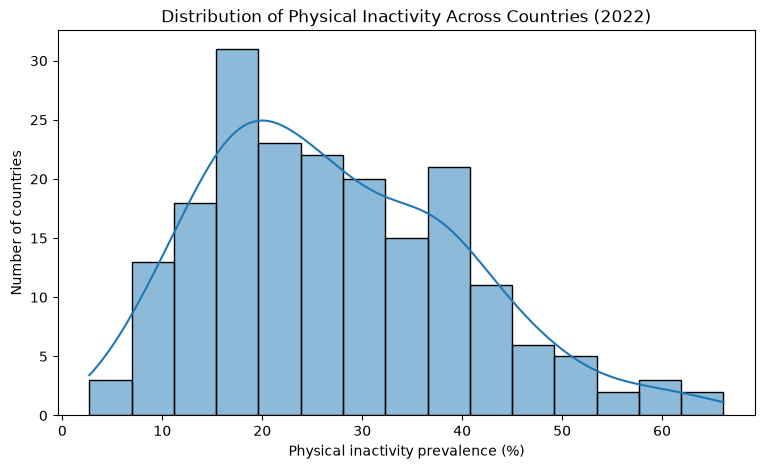

In [137]:
# Histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    data=who_2022_adults,
    x="NumericValue",
    bins=15,
    kde=True
)

plt.title("Distribution of Physical Inactivity Across Countries (2022)")
plt.xlabel("Physical inactivity prevalence (%)")
plt.ylabel("Number of countries")
plt.show()



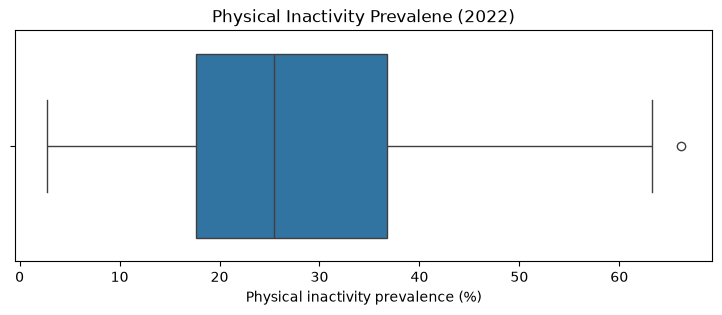

In [ ]:
# Boxplot
plt.figure(figsize=(9, 3))

sns.boxplot(data=who_2022_adults, x="NumericValue")

plt.title("Physical Inactivity Prevalence (2022)")
plt.xlabel("Physical inactivity prevalence (%)")
plt.show()

## 2.2 Eurostat Obesity

The Eurostat obesity dataset is provided in JSON-stat format rather than
as a traditional table.

JSON-stat stores observations in a compact structure:
- `id` identifies the dataset dimensions.
- `size` defines the number of categories in each dimension.
- `dimension` contains the category codes and their labels.
- `value` contains the actual observations, stored using flat indexes.
- `status` contains flags describing the reliability or status of observations.

For this project, we are interested in the percentage of adults classified
as obese (`BMI_GE30`) in 2022.

In [ ]:
# Inspect the top-level structure
obesity_json.keys()

dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])

In [ ]:
# Inspect the dimensions and their sizes
print("Dimensions:", obesity_json["id"])
print("Dimension sizes:", obesity_json["size"])

Dimensions: ['freq', 'unit', 'bmi', 'geo', 'time']
Dimension sizes: [1, 1, 3, 40, 1]


In [ ]:
# Inspect the categories available in each dimension
for dimension in obesity_json["id"]:
    dimension_info = obesity_json["dimension"][dimension]

    print(f"\nDimension: {dimension}")
    print("Description:", dimension_info["label"])
    print("Categories:", dimension_info["category"]["index"])
    print("Labels:", dimension_info["category"].get("label", {}))


Dimension: freq
Description: Time frequency
Categories: {'A': 0}
Labels: {'A': 'Annual'}

Dimension: unit
Description: Unit of measure
Categories: {'PC': 0}
Labels: {'PC': 'Percentage'}

Dimension: bmi
Description: Body Mass Index
Categories: {'BMI_GE25': 0, 'BMI25-29': 1, 'BMI_GE30': 2}
Labels: {'BMI_GE25': 'Overweight', 'BMI25-29': 'Pre-obese', 'BMI_GE30': 'Obese'}

Dimension: geo
Description: Geopolitical entity (reporting)
Categories: {'EU27_2020': 0, 'EA21': 1, 'EA20': 2, 'BE': 3, 'BG': 4, 'CZ': 5, 'DK': 6, 'DE': 7, 'EE': 8, 'IE': 9, 'EL': 10, 'ES': 11, 'FR': 12, 'HR': 13, 'IT': 14, 'CY': 15, 'LV': 16, 'LT': 17, 'LU': 18, 'HU': 19, 'MT': 20, 'NL': 21, 'AT': 22, 'PL': 23, 'PT': 24, 'RO': 25, 'SI': 26, 'SK': 27, 'FI': 28, 'SE': 29, 'IS': 30, 'NO': 31, 'CH': 32, 'AL': 33, 'BA': 34, 'ME': 35, 'MK': 36, 'RS': 37, 'TR': 38, 'UK': 39}
Labels: {'EU27_2020': 'European Union - 27 countries (from 2020)', 'EA21': 'Euro area – 21 countries (from 2026)', 'EA20': 'Euro area – 20 countries (2023

### Understanding the Flat Index

JSON-stat stores observations using a single flat index.

The index represents a position across all dataset dimensions.
Because the dimensions have a fixed order, we can calculate the
position of each category using the dimension sizes.

In this dataset, `freq`, `unit`, and `time` each have only one
category. Therefore, the flat index can be calculated as:

`flat_index = bmi_position * number_of_geographies + geo_position`

We can use this formula to identify which country and BMI category
each observation belongs to.

In [ ]:
# Get the category indexes
bmi_index = obesity_json["dimension"]["bmi"]["category"]["index"]
geo_index = obesity_json["dimension"]["geo"]["category"]["index"]

print("BMI categories:", bmi_index)
print("Geography categories:", geo_index)

BMI categories: {'BMI_GE25': 0, 'BMI25-29': 1, 'BMI_GE30': 2}
Geography categories: {'EU27_2020': 0, 'EA21': 1, 'EA20': 2, 'BE': 3, 'BG': 4, 'CZ': 5, 'DK': 6, 'DE': 7, 'EE': 8, 'IE': 9, 'EL': 10, 'ES': 11, 'FR': 12, 'HR': 13, 'IT': 14, 'CY': 15, 'LV': 16, 'LT': 17, 'LU': 18, 'HU': 19, 'MT': 20, 'NL': 21, 'AT': 22, 'PL': 23, 'PT': 24, 'RO': 25, 'SI': 26, 'SK': 27, 'FI': 28, 'SE': 29, 'IS': 30, 'NO': 31, 'CH': 32, 'AL': 33, 'BA': 34, 'ME': 35, 'MK': 36, 'RS': 37, 'TR': 38, 'UK': 39}


### Extracting Obesity Data

We only need the `BMI_GE30` category, representing the percentage
of adults classified as obese.

We will:
1. Identify the position of `BMI_GE30`.
2. Iterate through all geographical categories.
3. Calculate the flat index for each country.
4. Retrieve the corresponding observation and status flag.
5. Store the results in a Pandas DataFrame.

In [ ]:
# Get the position of the obesity category
obese_position = bmi_index["BMI_GE30"]

# Reverse the geography index: position -> country code
geo_codes = {position: code for code, position in geo_index.items()}

#Extract obesity observations
obesity_data = []

number_of_geographies = len(geo_index)


for geo_position, country_code in geo_codes.items():

    flat_index = obese_position * number_of_geographies + geo_position

    value = obesity_json["value"].get(str(flat_index))
    status = obesity_json.get("status", {}).get(str(flat_index))

    if value is not None:
        obesity_data.append({
            "geo": country_code,
            "obesity_pct": value,
            "status": status
        })

obesity_df = pd.DataFrame(obesity_data)

### Initial Observations

In [ ]:
obesity_df.shape

(37, 3)

In [ ]:
obesity_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   geo          37 non-null     str    
 1   obesity_pct  37 non-null     float64
 2   status       6 non-null      str    
dtypes: float64(1), str(2)
memory usage: 1020.0 bytes


In [ ]:
obesity_df.isnull().sum()

geo             0
obesity_pct     0
status         31
dtype: int64

In [ ]:
obesity_df.sort_values("obesity_pct", ascending=False).head(10)

,geo,obesity_pct,status
18,MT,26.1,NaN
28,IS,24.2,NaN
14,LV,23.3,NaN
17,HU,22.2,NaN
6,EE,22.1,NaN
26,FI,21.2,NaN
15,LT,20.6,u
36,TR,20.1,NaN
7,IE,19.8,u
5,DK,19.0,NaN


In [141]:
obesity_df["geo"].sort_values().tolist()

['AL',
 'AT',
 'BA',
 'BE',
 'BG',
 'CH',
 'CY',
 'CZ',
 'DK',
 'EA20',
 'EE',
 'EL',
 'ES',
 'EU27_2020',
 'FI',
 'FR',
 'HR',
 'HU',
 'IE',
 'IS',
 'IT',
 'LT',
 'LU',
 'LV',
 'ME',
 'MK',
 'MT',
 'NL',
 'NO',
 'PL',
 'PT',
 'RO',
 'RS',
 'SE',
 'SI',
 'SK',
 'TR']

In [142]:
# Exclude geographical aggregates
aggregates = ["EA20", "EU27_2020"]

obesity_countries = obesity_df[
    ~obesity_df["geo"].isin(aggregates)
].copy()

In [143]:
obesity_countries.shape

(35, 3)

In [144]:
obesity_countries["geo"].sort_values().tolist()

['AL',
 'AT',
 'BA',
 'BE',
 'BG',
 'CH',
 'CY',
 'CZ',
 'DK',
 'EE',
 'EL',
 'ES',
 'FI',
 'FR',
 'HR',
 'HU',
 'IE',
 'IS',
 'IT',
 'LT',
 'LU',
 'LV',
 'ME',
 'MK',
 'MT',
 'NL',
 'NO',
 'PL',
 'PT',
 'RO',
 'RS',
 'SE',
 'SI',
 'SK',
 'TR']

The extracted Eurostat dataset contains 35 individual countries with available obesity prevalence data for 2022, after excluding two geographical aggregates (Euro area and European Union).

The highest observed prevalence is in Malta (26.1%), followed by Iceland (24.2%) and Latvia (23.3%).

Some observations carry reliability flags. These flags are retained for further data-quality assessment rather than being removed at this stage.

These are preliminary descriptive findings. Further validation of data quality and geographical coverage, as well as integration with the physical activity dataset, is required before drawing conclusions.

### Data Reliability Flags

In [ ]:
obesity_df["status"].value_counts(dropna=False)

status
NaN    31
u       4
e       2
Name: count, dtype: int64

The Eurostat dataset includes status flags that provide additional information about individual observations.

The extracted data contains the following flags:

- `u` – Low reliability
- `e` – Estimated value
- No flag – No additional status flag is provided for the observation.

These flags are retained in the extracted dataset so that data quality can be considered during subsequent analysis.

The absence of a status flag does not indicate a missing observation.

### Descriptive Statistics

In [ ]:
obesity_df["obesity_pct"].describe()

count    37.000000
mean     16.448649
std       4.313842
min       7.100000
25%      13.800000
50%      16.100000
75%      19.000000
max      26.100000
Name: obesity_pct, dtype: float64

The extracted obesity dataset contains 37 observations.

The mean is 16.45%, and the median is 16.10%. That suggests the distribution is fairly centred around similar values, but the histogram will help us assess its shape.

The standard deviation is 4.31 percentage points, indicating
variation in obesity prevalence across the observed geographical
units.

The observed values range from 7.1% to 26.1%. The middle 50%
of observations fall between 13.8% and 19.0%.

These statistics provide an initial overview of the dataset.
They do not yet describe the relationship between obesity and
physical inactivity.

### Visualising the Distribution

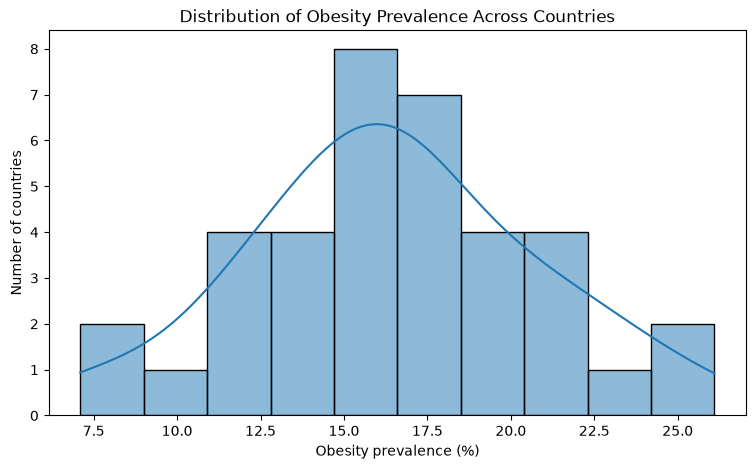

In [135]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=obesity_df,
    x="obesity_pct",
    bins=10,
    kde=True
)

plt.title("Distribution of Obesity Prevalence Across Countries")
plt.xlabel("Obesity prevalence (%)")
plt.ylabel("Number of countries")

plt.show()

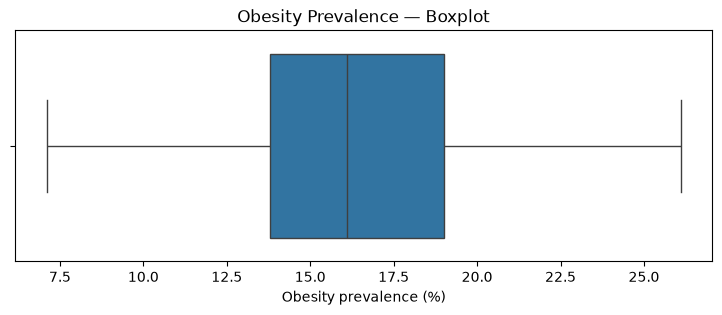

In [136]:
plt.figure(figsize=(9, 3))

sns.boxplot(
    data=obesity_df,
    x="obesity_pct"
)

plt.title("Obesity Prevalence — Boxplot")
plt.xlabel("Obesity prevalence (%)")

plt.show()

# 3. Data Preparation
# 4. Data Cleaning and Validation
# 5. Data Integration